In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
medium = pd.read_json("contributors_commits_medium.json", orient='index', typ='series')
# Convert to DataFrame with proper column name
medium = medium.to_frame(name='commit_count')
medium.index.name = 'author_id'
medium = medium.reset_index()

In [3]:
big = pd.read_json("contributors_commits_big.json", orient='index', typ='series')
# Convert to DataFrame with proper column name
big = big.to_frame(name='commit_count')
big.index.name = 'author_id'
big = big.reset_index()

In [4]:
def display(data):
    commit_distribution = data['commit_count'].value_counts().sort_index()

    plt.figure(figsize=(12, 6))
    plt.barh(range(len(commit_distribution)), commit_distribution.values)
    plt.yticks(range(len(commit_distribution)), commit_distribution.index)
    plt.ylabel('Number of Commits')
    plt.xlabel('Number of Contributors')
    plt.title('Distribution of Contributors by Commit Count')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

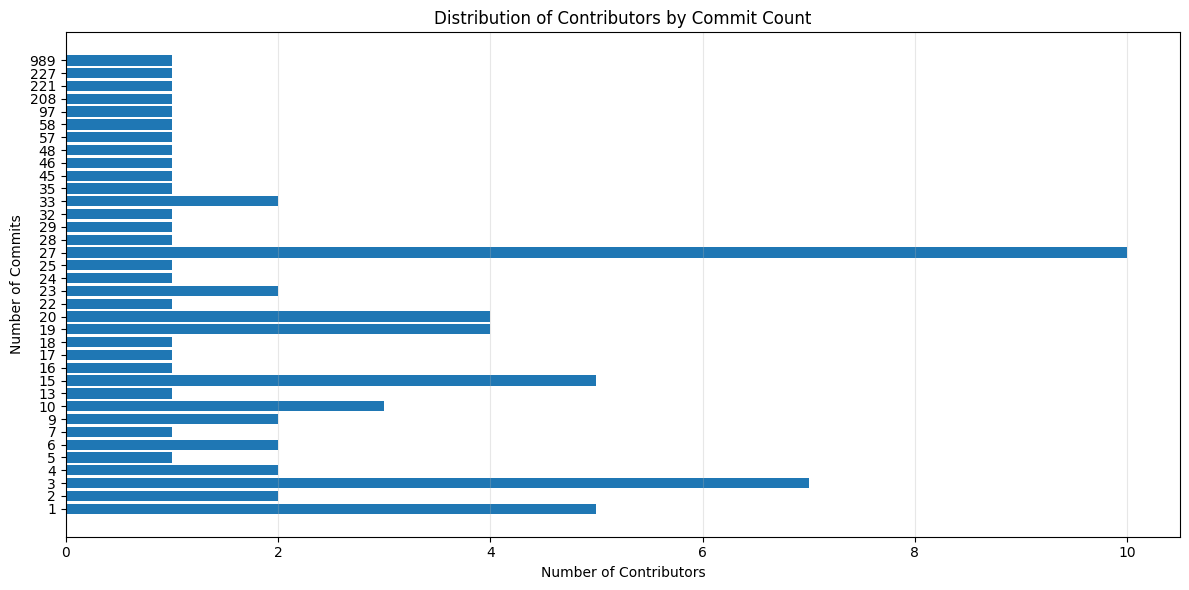

In [5]:
display(medium)

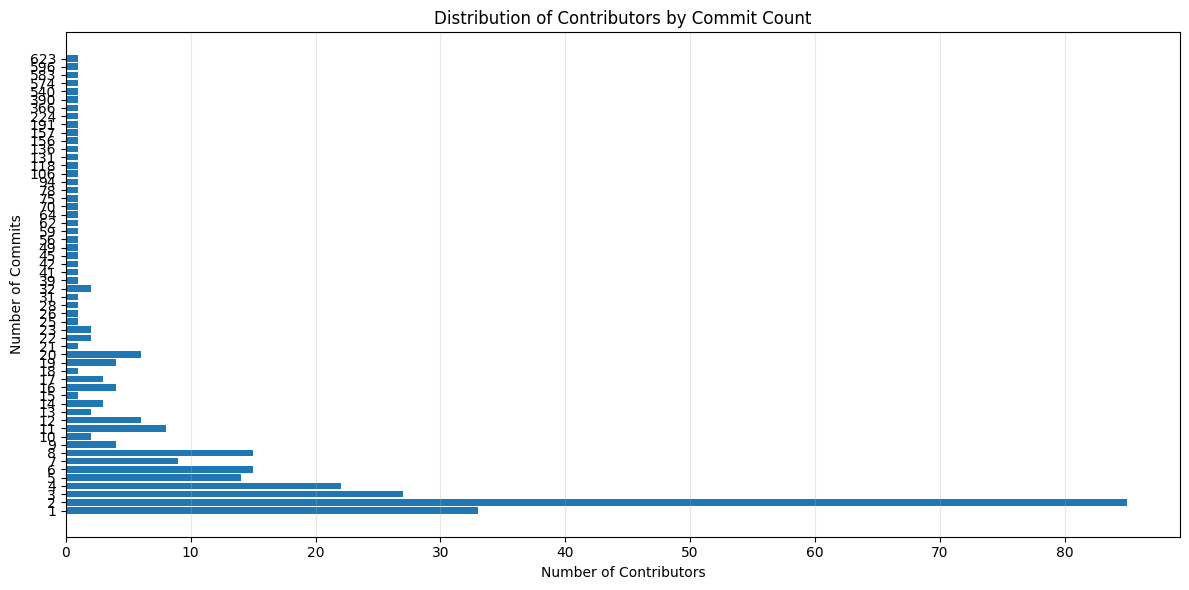

In [6]:
display(big)

In [7]:
import json

# Load the new JSON structure
with open("contributors_commits_all.json", "r") as f:
    repos_data = json.load(f)

# Collect value_counts for each repository
all_distributions = []

for repo_id, authors in repos_data.items():
    # Convert to Series and get value_counts
    commit_counts = pd.Series(authors.values())
    distribution = commit_counts.value_counts().sort_index()
    all_distributions.append(distribution)

# Create a combined DataFrame with all distributions
combined = pd.DataFrame(all_distributions).fillna(0)

# Calculate the average profile
average_profile = combined.mean(axis=0).sort_index()

print(f"Processed {len(all_distributions)} repositories")
average_profile

Processed 442 repositories


1         37.606335
2         25.049774
3         16.617647
4         14.325792
5         10.690045
            ...    
427054     0.002262
441091     0.002262
450377     0.002262
521916     0.002262
610553     0.002262
Length: 6026, dtype: float64

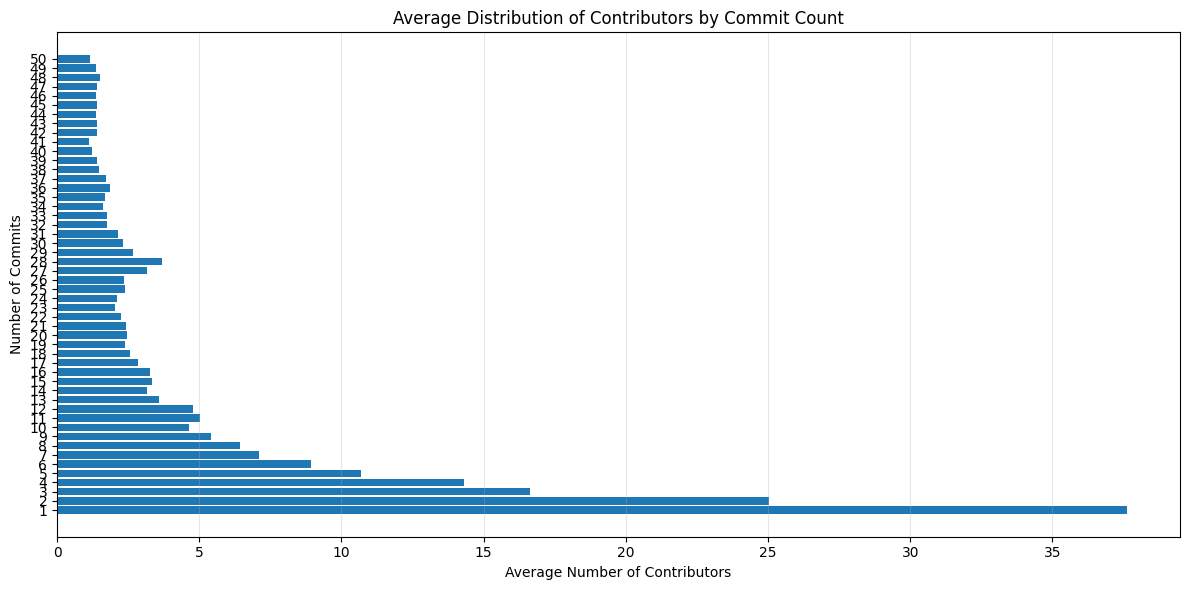

In [9]:

filtered_profile = average_profile[average_profile.index <= 50]

def display_profile(profile_series):
    plt.figure(figsize=(12, 6))
    plt.barh(range(len(profile_series)), profile_series.values)
    plt.yticks(range(len(profile_series)), profile_series.index)
    plt.ylabel('Number of Commits')
    plt.xlabel('Average Number of Contributors')
    plt.title('Average Distribution of Contributors by Commit Count')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

display_profile(filtered_profile)